# Corovans — will the player die in this wave?

Telemetry of the browser game *Corovans* (you are a bandit robbing caravans; waves of guards get harder).
One row = one wave a player started. Features describe the player's state **before** the wave;
target `died` = the player died during this wave.

Use case: predict the death risk at wave start to tune difficulty (e.g. drop a medkit or soften
the wave when the risk is high) and to find unbalanced cards/waves.

Data: `data/waves.csv`, built by `prepare_data.py` from raw session JSON (names removed, ids hashed).

HP is logged only when the player is hit. Between hits `prepare_data.py` simulates healing with the
game's formulas (regen, medkit, maxHp/glassCannon cards, fortify, lifesteal, novice mercy heal);
each logged hit resyncs HP to the truth. Checked against 178k logged hits: mean error of HP before
a hit drops from 6.5 to 2.8 HP (61% exact vs 28% without healing).

The game changed between versions 1.1 and 1.6 (regen rebalance, new cards and guards), so the
evaluation is **time-based**: train on older sessions, test on the newest version.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from features import add_features, risk_formula, feature_columns, fit_caps, clip_outliers, to_dicts

df = pd.read_csv('data/waves.csv')
df.shape

(9404, 55)

In [2]:
df.head().T.head(25)

,0,1,2,3,4
session_id,5eddf62cdf,5eddf62cdf,5eddf62cdf,5eddf62cdf,5eddf62cdf
player_id,5eddf62cdf,5eddf62cdf,5eddf62cdf,5eddf62cdf,5eddf62cdf
game_version,unknown,unknown,unknown,unknown,unknown
started_at,2026-05-09T17:31:13.954Z,2026-05-09T17:31:13.954Z,2026-05-09T17:31:13.954Z,2026-05-09T17:31:13.954Z,2026-05-09T17:31:13.954Z
prior_sessions,0,0,0,0,0
prior_best_wave,0,0,0,0,0
wave,1,2,3,4,5
boss,0,0,0,0,1
caravans,1,2,2,3,2
guards,1,2,5,7,10


In [3]:
df.isnull().sum().sum()

np.int64(0)

## Target

In [4]:
df.died.value_counts(normalize=True)

died
0    0.888133
1    0.111867
Name: proportion, dtype: float64

## Sessions and players

In [5]:
print('sessions', df.session_id.nunique(), 'players', df.player_id.nunique())
df.groupby('session_id').wave.max().describe()

sessions 1052 players 459


count    1052.000000
mean        8.777567
std         6.501991
min         1.000000
25%         5.000000
50%         7.000000
75%        11.000000
max        80.000000
Name: wave, dtype: float64

## Death rate by wave

Boss waves every 5 waves.

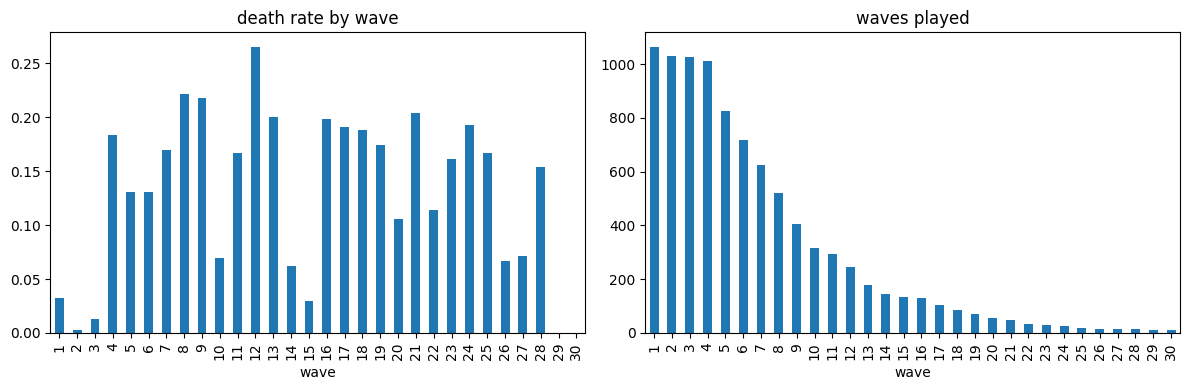

In [6]:
by_wave = df[df.wave <= 30].groupby('wave').agg(died=('died', 'mean'), n=('died', 'size'))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
by_wave.died.plot.bar(ax=ax[0], title='death rate by wave')
by_wave.n.plot.bar(ax=ax[1], title='waves played')
plt.tight_layout()

In [7]:
df.groupby('boss').died.agg(['mean', 'size'])

,mean,size
boss,,
0,0.113429,8005
1,0.102931,1399


## HP at wave start

In [8]:
hp_bucket = pd.cut(df.hp_frac, [-0.01, 0.25, 0.5, 0.75, 0.99, 1.0])
df.groupby(hp_bucket, observed=True).died.agg(['mean', 'size'])

,mean,size
hp_frac,,
"(-0.01, 0.25]",0.447368,266
"(0.25, 0.5]",0.275239,941
"(0.5, 0.75]",0.178672,1416
"(0.75, 0.99]",0.054125,3030
"(0.99, 1.0]",0.068515,3751


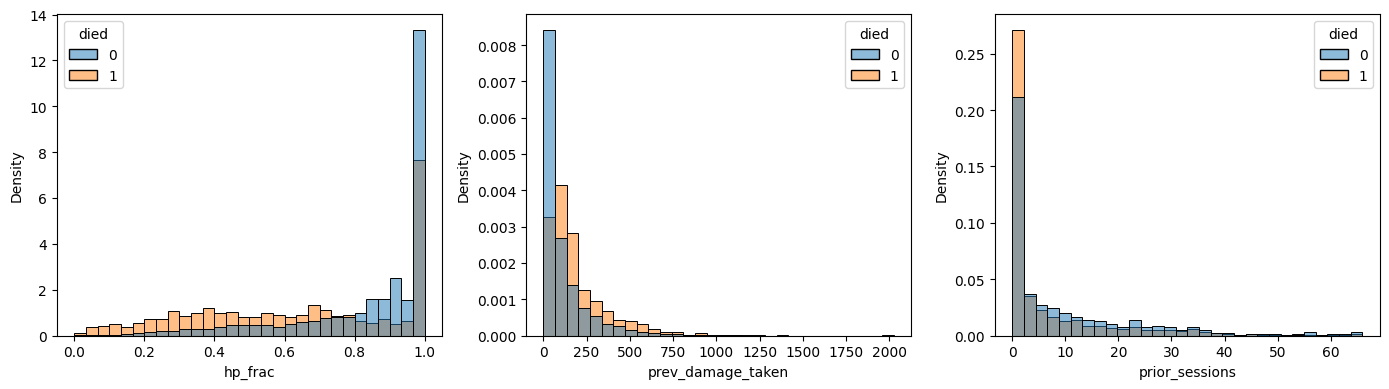

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['hp_frac', 'prev_damage_taken', 'prior_sessions']):
    sns.histplot(data=df, x=col, hue='died', stat='density', common_norm=False, bins=30, ax=ax)
plt.tight_layout()

## Game versions and balance drift

Most data comes from the launch weeks; the current game (after the regen rebalance on 2026-06-07)
has far fewer players. Death rates differ between versions.

In [10]:
df['date'] = df.started_at.str[:10]
df.groupby('game_version').agg(
    first=('date', 'min'), last=('date', 'max'),
    waves=('died', 'size'), deaths=('died', 'sum'),
    death_rate=('died', 'mean'), players=('player_id', 'nunique'),
).sort_values('first').round(3)

,first,last,waves,deaths,death_rate,players
game_version,,,,,,
unknown,2026-05-09,2026-05-13,3125,476,0.152,321
1.1,2026-05-10,2026-05-13,428,46,0.107,28
1.2,2026-05-11,2026-05-26,4014,360,0.090,97
1.3,2026-05-26,2026-06-06,360,24,0.067,14
1.4,2026-06-07,2026-06-07,7,1,0.143,1
1.5,2026-06-07,2026-08-16,864,74,0.086,15
1.6,2026-08-16,2026-10-12,606,71,0.117,12


## Feature engineering

Ratios of expected damage to the HP buffer (see `features.py`).

In [11]:
df = add_features(df.drop(columns='date'))
categorical, numerical = feature_columns(df)
df[['dmg_per_guard', 'expected_damage', 'expected_damage_to_hp', 'prev_damage_to_hp', 'guard_growth']].describe().T

,count,mean,std,min,25%,50%,75%,max
dmg_per_guard,9404.0,8.914993,7.010444,0.000000,4.000000,8.000000,12.444444,112.000000
expected_damage,9404.0,136.161550,168.253280,0.000000,32.000000,80.000000,179.200000,2065.517949
expected_damage_to_hp,9404.0,1.949964,3.943527,0.000000,0.270871,0.881833,2.462929,201.692308
prev_damage_to_hp,9404.0,1.590501,3.210104,0.000000,0.166277,0.646092,2.039295,138.000000
guard_growth,9404.0,1.438496,0.497358,0.520677,1.000000,1.312500,1.750000,3.000000


In [12]:
df.pivot_table(index='era', columns=df.wave.clip(upper=12), values='died', aggfunc='mean').round(2)

wave,1,2,3,4,5,6,7,8,9,10,11,12
era,,,,,,,,,,,,
new,0.05,0.0,0.01,0.18,0.10,0.14,0.14,0.21,0.28,0.02,0.17,0.09
old,0.03,0.0,0.01,0.18,0.14,0.13,0.18,0.22,0.21,0.08,0.17,0.17


### Feature importance: ROC AUC of each numerical feature

Negative sign = negative relation (shown as `-(1 - AUC)`).

In [13]:
aucs = {}
for col in numerical:
    auc = roc_auc_score(df.died, df[col])
    aucs[col] = auc if auc >= 0.5 else -(1 - auc)
pd.Series(aucs).sort_values(key=abs, ascending=False).head(20)

expected_damage_to_hp    0.769250
prev_damage_to_hp        0.758643
expected_damage          0.726454
prev_damage_taken        0.715316
hp_frac                 -0.695402
dmg_per_guard            0.672847
guards                   0.657321
caravans                 0.656333
hp_start                -0.655726
guards_killed            0.648615
wave                     0.647971
caravans_robbed          0.647093
gold_earned              0.647084
elapsed_s                0.646498
prev_guards              0.644572
prev_duration_s          0.643096
gold_spent               0.624787
cards_total              0.614218
prior_best_wave         -0.589259
log_prior_best_wave     -0.589259
dtype: float64

### Is the relation stable across versions?

AUC of the simple risk formula (`expected damage / HP`, see below) inside each version:
the ranking power barely changes, while the base death rate does.

In [14]:
pd.DataFrame({
    v: {'auc': roc_auc_score(g.died, risk_formula(g)), 'death_rate': g.died.mean(), 'waves': len(g)}
    for v, g in df.groupby('game_version') if len(g) > 100
}).T.round(3)

,auc,death_rate,waves
1.1,0.775,0.107,428.0
1.2,0.777,0.090,4014.0
1.3,0.793,0.067,360.0
1.5,0.793,0.086,864.0
1.6,0.790,0.117,606.0
unknown,0.795,0.152,3125.0


## Split: time-based

* **test** = sessions of the newest version (1.6, from 2026-08-16) — "how the model works on the
  current game";
* **train** = all earlier sessions (all versions, both balance eras). Training on old versions
  only underestimates the risk in the new ones, training on new ones only has too little data —
  using all of them gave the best results.
* Model selection: 5-fold cross-validation **grouped by player** on train, so the same player is
  never in both parts.

In [15]:
TEST_FROM = '2026-08-16'
is_test = df.started_at.str[:10] >= TEST_FROM
df_train = df[~is_test].reset_index(drop=True)
df_test = df[is_test].reset_index(drop=True)

for name, d in [('train', df_train), ('test', df_test)]:
    print(f'{name}: {len(d)} waves, {d.died.sum()} deaths, {d.player_id.nunique()} players, '
          f'death rate {d.died.mean():.3f}')

train: 8769 waves, 978 deaths, 451 players, death rate 0.112
test: 635 waves, 74 deaths, 12 players, death rate 0.117


## Outliers

Long runs (up to wave 80) and AFK sessions (13 h) give extreme cumulative counts and durations.
Clip every numerical feature at its 99th percentile, computed on the training part only
(inside each CV fold too).

In [16]:
caps = fit_caps(df_train, numerical)
clip_outliers(df_train, caps)[['elapsed_s', 'prev_duration_s', 'guards', 'guards_killed']].max()

elapsed_s          2701.892
prev_duration_s     121.164
guards              255.640
guards_killed      4148.560
dtype: float64

## Evaluation helpers

In [17]:
kfold = GroupKFold(n_splits=5)

def cv_auc(fit_predict, df=df_train):
    scores = []
    for tr_idx, va_idx in kfold.split(df, groups=df.player_id):
        tr, va = df.iloc[tr_idx], df.iloc[va_idx]
        scores.append(roc_auc_score(va.died, fit_predict(tr, va)))
    return np.mean(scores), np.std(scores)

def bootstrap_ci(y, score, groups, n=500, seed=1):
    rng = np.random.default_rng(seed)
    y, score = np.asarray(y), np.asarray(score)
    by_player = {g: np.where(groups == g)[0] for g in np.unique(groups)}
    players = list(by_player)
    aucs = []
    for _ in range(n):
        idx = np.concatenate([by_player[p] for p in rng.choice(players, len(players))])
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], score[idx]))
    return np.percentile(aucs, [2.5, 97.5])

results = {}

def report(name, fit_predict):
    cv_mean, cv_std = cv_auc(fit_predict)
    test_score = fit_predict(df_train, df_test)
    lo, hi = bootstrap_ci(df_test.died, test_score, df_test.player_id.values)
    results[name] = {'cv_auc': cv_mean, 'cv_std': cv_std,
                     'test_auc': roc_auc_score(df_test.died, test_score), 'test_ci_low': lo, 'test_ci_high': hi}
    return pd.Series(results[name]).round(3)

## Baseline 1: a formula, no ML

```
risk = dmg_per_guard * guards^a / hp_start^b / (1 + prior_best_wave)^x
```
"How much damage the player is about to take compared with the HP left", discounted by experience.
The exponents are picked by grid search on train.

In [18]:
grid = [(a, b, x) for a in [0.75, 1, 1.25, 1.5] for b in [1, 1.5, 2] for x in [0, 0.25, 0.5, 0.75]]
best = max(grid, key=lambda p: roc_auc_score(df_train.died, risk_formula(df_train, *p)))
best

(1.25, 2, 0.5)

In [19]:
report('formula, a=b=1, x=0', lambda tr, va: risk_formula(va, 1, 1, 0))
report('formula, tuned', lambda tr, va: risk_formula(va, *best))

cv_auc          0.792
cv_std          0.013
test_auc        0.795
test_ci_low     0.650
test_ci_high    0.850
dtype: float64

## Baseline 2: logistic regression

In [20]:
invariant = ['wave', 'boss', 'caravans', 'guards', 'hp_start', 'max_hp', 'hp_frac',
             'prev_guards', 'prev_damage_taken', 'dmg_per_guard', 'expected_damage',
             'expected_damage_to_hp', 'prev_damage_to_hp', 'guard_growth',
             'prior_sessions', 'prior_best_wave', 'log_prior_best_wave']

def logreg(cat, num, C=1.0):
    def fit_predict(tr, va):
        caps = fit_caps(tr, num)
        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(to_dicts(clip_outliers(tr, caps), cat, num))
        X_va = dv.transform(to_dicts(clip_outliers(va, caps), cat, num))
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_tr, tr.died)
        return model.predict_proba(X_va)[:, 1]
    return fit_predict

report('logreg, all features', logreg(categorical, numerical))

cv_auc          0.816
cv_std          0.019
test_auc        0.796
test_ci_low     0.718
test_ci_high    0.868
dtype: float64

In [21]:
report('logreg, version-invariant features', logreg(['era'], invariant))

cv_auc          0.792
cv_std          0.009
test_auc        0.820
test_ci_low     0.776
test_ci_high    0.856
dtype: float64

## Tree-based models

Same protocol: hyperparameters are tuned by grouped 5-fold CV on train, then the best setting is
evaluated once on the test version. Trees don't need outlier clipping, but it doesn't hurt.

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from itertools import product

def sk_model(make_model, cat, num):
    def fit_predict(tr, va):
        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(to_dicts(tr, cat, num))
        X_va = dv.transform(to_dicts(va, cat, num))
        return make_model().fit(X_tr, tr.died).predict_proba(X_va)[:, 1]
    return fit_predict

feature_sets = {'all': (categorical, numerical), 'invariant': (['era'], invariant)}

def tune(make_model, grid):
    rows = []
    for fs, (cat, num) in feature_sets.items():
        for params in grid:
            mean, std = cv_auc(sk_model(lambda: make_model(**params), cat, num))
            rows.append({'features': fs, **params, 'cv_auc': mean, 'cv_std': std})
    return pd.DataFrame(rows).sort_values('cv_auc', ascending=False)

def grid_of(**axes):
    return [dict(zip(axes, values)) for values in product(*axes.values())]

def report_best(name, make_model, scores):
    for fs, (cat, num) in feature_sets.items():
        best = scores[scores.features == fs].iloc[0]
        params = {k: best[k] for k in scores.columns if k not in ('features', 'cv_auc', 'cv_std')}
        params = {k: (None if pd.isna(v) else v) for k, v in params.items()}
        params = {k: (int(v) if isinstance(v, float) and v.is_integer() else v) for k, v in params.items()}
        print(fs, params)
        report(f'{name}, {fs}', sk_model(lambda: make_model(**params), cat, num))

### Decision tree

In [23]:
def make_dt(max_depth, min_samples_leaf):
    return DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=1)

dt_scores = tune(make_dt, grid_of(max_depth=[4, 6, 8], min_samples_leaf=[50, 100, 200]))
dt_scores.head(6).round(3)

,features,max_depth,min_samples_leaf,cv_auc,cv_std
5,all,6,200,0.796,0.012
8,all,8,200,0.796,0.013
14,invariant,6,200,0.796,0.017
13,invariant,6,100,0.796,0.015
4,all,6,100,0.796,0.015
7,all,8,100,0.796,0.013


In [24]:
report_best('decision tree', make_dt, dt_scores)

all {'max_depth': np.int64(6), 'min_samples_leaf': np.int64(200)}


invariant {'max_depth': np.int64(6), 'min_samples_leaf': np.int64(200)}


### Random forest

In [25]:
def make_rf(max_depth, min_samples_leaf):
    return RandomForestClassifier(n_estimators=200, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                  max_features='sqrt', n_jobs=-1, random_state=1)

rf_scores = tune(make_rf, grid_of(max_depth=[10, None], min_samples_leaf=[10, 20, 50]))
rf_scores.head(6).round(3)

,features,max_depth,min_samples_leaf,cv_auc,cv_std
3,all,NaN,10,0.835,0.016
4,all,NaN,20,0.835,0.014
0,all,10.0,10,0.834,0.016
1,all,10.0,20,0.834,0.014
5,all,NaN,50,0.831,0.013
2,all,10.0,50,0.831,0.013


In [26]:
report_best('random forest', make_rf, rf_scores)

all {'max_depth': None, 'min_samples_leaf': np.int64(10)}


invariant {'max_depth': 10, 'min_samples_leaf': np.int64(20)}


### XGBoost

In [27]:
def make_xgb(max_depth, min_child_weight, n_estimators, learning_rate=0.03):
    return xgb.XGBClassifier(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                             min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
                             n_jobs=8, random_state=1, verbosity=0)

xgb_scores = tune(make_xgb, grid_of(max_depth=[4, 6, 8], min_child_weight=[20, 50], n_estimators=[300, 600]))
xgb_scores.head(6).round(3)

,features,max_depth,min_child_weight,n_estimators,cv_auc,cv_std
4,all,6,20,300,0.842,0.013
0,all,4,20,300,0.842,0.014
8,all,8,20,300,0.841,0.014
3,all,4,50,600,0.840,0.015
6,all,6,50,300,0.840,0.014
7,all,6,50,600,0.840,0.015


In [28]:
report_best('xgboost', make_xgb, xgb_scores)

all {'max_depth': np.int64(6), 'min_child_weight': np.int64(20), 'n_estimators': np.int64(300)}


invariant {'max_depth': np.int64(4), 'min_child_weight': np.int64(20), 'n_estimators': np.int64(300)}


## Comparison

In [29]:
summary = pd.DataFrame(results).T.sort_values('cv_auc', ascending=False)
summary.round(3)

,cv_auc,cv_std,test_auc,test_ci_low,test_ci_high
"xgboost, all",0.842,0.013,0.812,0.745,0.883
"random forest, all",0.835,0.016,0.816,0.741,0.883
"xgboost, invariant",0.826,0.013,0.806,0.739,0.867
"random forest, invariant",0.823,0.014,0.806,0.741,0.876
"logreg, all features",0.816,0.019,0.796,0.718,0.868
"decision tree, all",0.796,0.012,0.753,0.683,0.858
"decision tree, invariant",0.796,0.017,0.787,0.716,0.867
"logreg, version-invariant features",0.792,0.009,0.820,0.776,0.856
"formula, tuned",0.792,0.013,0.795,0.650,0.850
"formula, a=b=1, x=0",0.770,0.008,0.787,0.637,0.846


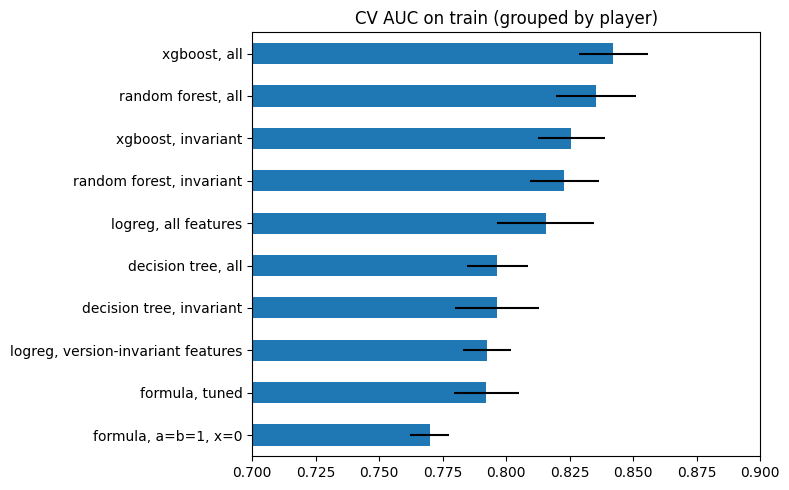

In [30]:
ax = summary.cv_auc.plot.barh(xerr=summary.cv_std, figsize=(8, 5), title='CV AUC on train (grouped by player)')
ax.set_xlim(0.7, 0.9)
ax.invert_yaxis()
plt.tight_layout()

## What does the best model look at?

In [31]:
best_xgb = xgb_scores[xgb_scores.features == 'all'].iloc[0]
xgb_params = {k: int(best_xgb[k]) for k in ['max_depth', 'min_child_weight', 'n_estimators']}
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(to_dicts(df_train, categorical, numerical))
model = make_xgb(**xgb_params).fit(X_train, df_train.died)
importance = pd.Series(model.feature_importances_, index=dv.get_feature_names_out())
importance.sort_values(ascending=False).head(15).round(3)

expected_damage_to_hp    0.101
caravans_robbed          0.060
prev_damage_to_hp        0.045
boss                     0.032
caravans                 0.032
log_prior_best_wave      0.030
game_version=unknown     0.030
hp_start                 0.028
prev_damage_taken        0.027
wave                     0.023
card_lifesteal           0.022
cards_total              0.021
hp_frac                  0.021
guards                   0.020
expected_damage          0.020
dtype: float32

## Conclusions

* **XGBoost on all features is the best model in cross-validation**: AUC 0.842 ± 0.013, vs 0.816
  for logistic regression and 0.792 for the non-ML formula. Random forest is close (0.835).
  It is the model I take forward (`max_depth=6, min_child_weight=20, n_estimators=300, eta=0.03`).
* On the newest version (test) tree ensembles reach 0.81–0.82, the formula 0.80. The gap shrinks
  there, but the test is small (12 players) and all 95% intervals overlap.
* A single decision tree is not better than the formula — ensembles are needed.
* Version-invariant features lose ~0.02 in CV for the ensembles and gain nothing reliable on test,
  so I keep all features; the version drift is handled by the time-based test.
* The most important feature is the engineered `expected_damage_to_hp` — the same idea as the
  formula, so ML mostly adds refinements on top of "expected damage vs HP".